# SimCLR

Two independently corrupted versions of the same digit form a positive pair. Embeddings from other digits in the batch supply negatives without consulting their labels.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Representation Learning folder.")

## Two views and a contrastive loss

The denominator contains every embedding except the anchor itself. The target points to the other view of the same image.

In [2]:
import copy
import matplotlib.pyplot as plt
import torch
from torch import nn
from gallery.vision import digits_split
from gallery.neural import seed_cpu
from gallery.representations import probe_encoders, update_teacher


def view(x):
    gain = 0.8 + 0.4 * torch.rand((len(x), 1))
    return (x * gain + 0.10 * torch.randn_like(x)).clamp(0, 1) * (torch.rand_like(x) > 0.13)


def nt_xent(a, b, temperature=0.22):
    z = nn.functional.normalize(torch.cat([a, b]), dim=1)
    logits = z @ z.T / temperature
    logits = logits.masked_fill(torch.eye(len(z), dtype=torch.bool), -torch.inf)
    partner = (torch.arange(len(z)) + len(a)) % len(z)
    return nn.functional.cross_entropy(logits, partner)

## Contrastive training

The projection head participates in the contrastive loss. The downstream probe uses the encoder output before that head.

In [3]:
seed_cpu()
train, test, y, y_test = digits_split()
X = torch.tensor(train).flatten(1)
T = torch.tensor(test).flatten(1)

encoder = nn.Sequential(nn.Linear(64, 96), nn.ReLU(), nn.Linear(96, 40))
initial = copy.deepcopy(encoder)
head = nn.Sequential(nn.Linear(40, 48), nn.ReLU(), nn.Linear(48, 24))
opt = torch.optim.AdamW([*encoder.parameters(), *head.parameters()], lr=0.0015)
history = []
for epoch in range(24):
    total = 0.0
    for ids in torch.randperm(len(X)).split(80):
        batch = X[ids]
        loss = nt_xent(head(encoder(view(batch))), head(encoder(view(batch))))
        opt.zero_grad()
        loss.backward()
        opt.step()
        total += loss.item() * len(ids)
    history.append(total / len(X))

## Downstream comparison

All three linear probes share the same train and test split.

Raw input: accuracy 0.969 | balanced accuracy 0.969 | macro F1 0.969
Random encoder: accuracy 0.951 | balanced accuracy 0.951 | macro F1 0.951
Trained encoder: accuracy 0.947 | balanced accuracy 0.946 | macro F1 0.947
Held-out mean feature SD: 0.2556 | Effective covariance rank: 7.67


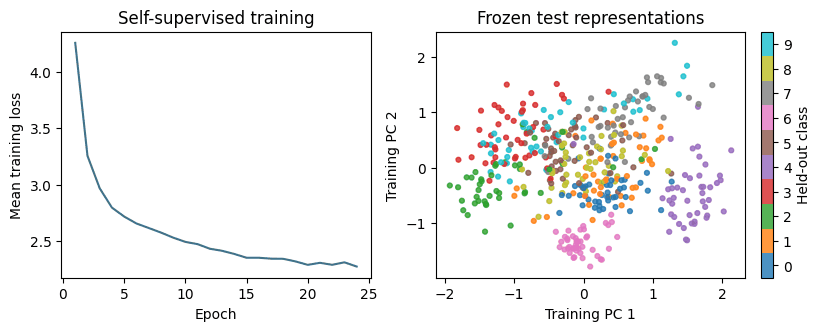

In [4]:
probe_encoders(initial, encoder, X, T, y, y_test, history)
plt.show()

## Reading the result

The loss rewards instance agreement. Class information is checked separately by the frozen digit probe.

## References

[Chen et al., A Simple Framework for Contrastive Learning of Visual Representations (2020)](https://proceedings.mlr.press/v119/chen20j.html)

[Alpaydin and Kaynak, Optical Recognition of Handwritten Digits, UCI, CC BY 4.0](https://doi.org/10.24432/C50P49)

[Frozen probes and masked-prediction training](../gallery/representations.py)